# Gaussian Quadrature

**Seong Cho** · ACME Volume 2, Lab 10

**Lab objective:** learn the basics of Gaussian quadrature and its application to numerical integration, build a class to perform numerical integration using Legendre and Chebyshev polynomials, compare the accuracy and speed of both types of Gaussian quadrature with the built-in SciPy package, and perform multivariate Gaussian quadrature.

<sub>Lab specification from the *Volume 2* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
import scipy.linalg as la
from scipy.integrate import quad
from scipy.integrate import nquad
from scipy.stats import norm
import matplotlib.pyplot as plt

## Legendre and Chebyshev Gaussian Quadrature

For any class of orthogonal polynomials $p \in \mathbb{R}[x; 2n+1]$ with corresponding weight function $w(x)$, there exists a set of points $\{x_i\}_{i=0}^n$ and weights $\{w_i\}_{i=0}^n$ such that

$$\int_a^b p(x)w(x)\,dx = \sum_{i=0}^n p(x_i)w_i.$$

Since this relationship is exact, a good approximation for $\int_a^b f(x)w(x)\,dx$ can be expected as long as $f(x)$ can be reasonably interpolated by a polynomial at the points $x_i$. In fact, if $f(x)$ is $2n+1$ times differentiable, the error of the approximation decreases as $n$ increases.

Gaussian quadrature can be performed using any basis of orthonormal polynomials, but the most commonly used are the Legendre polynomials and the Chebyshev polynomials. Their weight functions are $w_l(x) = 1$ and $w_c(x) = \frac{1}{\sqrt{1-x^2}}$, respectively, both defined on the open interval $(-1, 1)$.

## Problem 1: The `GaussianQuadrature` class

> **Problem 1.** Define a class for performing Gaussian quadrature. The constructor should accept an integer $n$ denoting the number of points and weights to use (this will be explained later) and a label indicating which class of polynomials to use. If the label is not either `"legendre"` or `"chebyshev"`, raise a `ValueError`; otherwise, store it as an attribute.
>
> The weight function $w(x)$ will show up later in the denominator of certain computations. Define the reciprocal function $w(x)^{-1} = 1/w(x)$ as a lambda function and save it as an attribute.

The class below is the finished one: it also contains the methods for Problems 2 (`points_weights()`), 3 (`basic()`), 4 (`integrate()`) and 6 (`integrate2d()`), each demonstrated under its own problem. The label is stored in `polytype` and $w(x)^{-1}$ in `w_inv`.

In [2]:
class GaussianQuadrature:
    """Class for integrating functions on arbitrary intervals using Gaussian
    quadrature with the Legendre polynomials or the Chebyshev polynomials.
    """
    # Problems 1 and 3
    def __init__(self, n, polytype="legendre"):
        """Calculate and store the n points and weights corresponding to the
        specified class of orthogonal polynomial (Problem 3). Also store the
        inverse weight function w(x)^{-1} = 1 / w(x).

        Parameters:
            n (int): Number of points and weights to use in the quadrature.
            polytype (string): The class of orthogonal polynomials to use in
                the quadrature. Must be either 'legendre' or 'chebyshev'.

        Raises:
            ValueError: if polytype is not 'legendre' or 'chebyshev'.
        """
        if polytype == "legendre":
            self.w_inv = lambda x: 1
        elif polytype == "chebyshev":
            self.w_inv = lambda x: np.sqrt(1 - x**2)
        else:
            raise ValueError("Polynomial type must be either legendre or chebyshev.")
        self.polytype = polytype
        self.points, self.weights = self.points_weights(n)

    # Problem 2
    def points_weights(self, n):
        """Calculate the n points and weights for Gaussian quadrature.

        Parameters:
            n (int): The number of desired points and weights.

        Returns:
            points ((n,) ndarray): The sampling points for the quadrature.
            weights ((n,) ndarray): The weights corresponding to the points.
        """
        B = None
        mu = 1
        if self.polytype == "chebyshev":
            B = [1/4 for i in range(n-1)]
            B[0] = 1/2
            mu = np.pi
        elif self.polytype == "legendre":
            B = [k**2/(4*k**2 - 1) for k in range(1, n)]
            mu = 2
        J1 = np.diag(np.sqrt(B), k=1)
        J2 = np.diag(np.sqrt(B), k=-1)
        J = J1 + J2
        x, eigvects = la.eig(J)
        w = [mu * v**2 for v in eigvects[0]]
        return np.real(x), np.real(w)


    # Problem 3
    def basic(self, f):
        """Approximate the integral of a f on the interval [-1,1]."""
        g = f(self.points) * self.w_inv(self.points)
        return np.dot(g, self.weights)

    # Problem 4
    def integrate(self, f, a, b):
        """Approximate the integral of a function on the interval [a,b].

        Parameters:
            f (function): Callable function to integrate.
            a (float): Lower bound of integration.
            b (float): Upper bound of integration.

        Returns:
            (float): Approximate value of the integral.
        """
        h = f((b-a)/2 * self.points + (a+b)/2)
        g = h * self.w_inv(self.points)
        return np.dot(g, self.weights) * (b-a)/2

    # Problem 6.
    def integrate2d(self, f, a1, b1, a2, b2):
        """Approximate the integral of the two-dimensional function f on
        the interval [a1,b1]x[a2,b2].

        Parameters:
            f (function): A function to integrate that takes two parameters.
            a1 (float): Lower bound of integration in the x-dimension.
            b1 (float): Upper bound of integration in the x-dimension.
            a2 (float): Lower bound of integration in the y-dimension.
            b2 (float): Upper bound of integration in the y-dimension.

        Returns:
            (float): Approximate value of the integral.
        """
        h = np.array([f((b1-a1)/2 * self.points + (a1+b1)/2, \
                        (b2-a2)/2 * y + (a2+b2)/2) for y in self.points])
        g = h.T * self.w_inv(self.points)
        g = (g.T * self.w_inv(self.points)).T
        return (b1-a1)*(b2-a2)/4*np.dot(self.weights, g@self.weights)

In [3]:
for label in ["legendre", "chebyshev"]:
    Q = GaussianQuadrature(5, label)
    print(f"{Q.polytype:9}  w_inv(0.6) = {Q.w_inv(0.6)}")
try:
    GaussianQuadrature(5, "hermite")
except ValueError as e:
    print("ValueError:", e)

legendre   w_inv(0.6) = 1
chebyshev  w_inv(0.6) = 0.8
ValueError: Polynomial type must be either legendre or chebyshev.


## Calculating Points and Weights

All sets of orthogonal polynomials $\{u_k\}_{k=0}^n$ satisfy the three-term recurrence relation

$$u_0 = 1, \qquad u_1 = x - \alpha_1, \qquad u_{k+1} = (x - \alpha_k)u_k - \beta_k u_{k-1}$$

for some coefficients $\{\alpha_k\}_{k=1}^n$ and $\{\beta_k\}_{k=1}^n$. For the Legendre polynomials they are

$$\alpha_k = 0, \qquad \beta_k = \frac{k^2}{4k^2 - 1},$$

and for the Chebyshev polynomials they are

$$\alpha_k = 0, \qquad \beta_k = \begin{cases} \frac{1}{2} & \text{if } k = 1 \\ \frac{1}{4} & \text{otherwise.} \end{cases}$$

Given these values, the corresponding Jacobi matrix is

$$J = \begin{bmatrix}
\alpha_1 & \sqrt{\beta_1} & 0 & \cdots & 0 \\
\sqrt{\beta_1} & \alpha_2 & \sqrt{\beta_2} & \cdots & 0 \\
0 & \sqrt{\beta_2} & \alpha_3 & \ddots & 0 \\
\vdots & & \ddots & \ddots & \sqrt{\beta_{n-1}} \\
0 & \cdots & & \sqrt{\beta_{n-1}} & \alpha_n
\end{bmatrix}.$$

According to the Golub-Welsch algorithm,¹ the $n$ eigenvalues of $J$ are the points $x_i$ to use in Gaussian quadrature, and the corresponding weights are $w_i = \mu_w(\mathbb{R})v_{i,0}^2$, where $v_{i,0}$ is the first entry of the $i$th eigenvector and $\mu_w(\mathbb{R}) = \int_{-\infty}^\infty w(x)\,dx$ is the measure of the weight function. Since the Legendre and Chebyshev weight functions have compact support on $(-1, 1)$, their measures are

$$\mu_{w_l}(\mathbb{R}) = \int_{-1}^1 1\,dx = 2, \qquad \mu_{w_c}(\mathbb{R}) = \int_{-1}^1 \frac{1}{\sqrt{1-x^2}}\,dx = \pi.$$

<sub>¹ See http://gubner.ece.wisc.edu/gaussquad.pdf for a complete treatment of the Golub-Welsch algorithm, including the computation of the recurrence relation coefficients for arbitrary orthogonal polynomials.</sub>

## Problem 2: Points and weights

> **Problem 2.** Write a method for your class that accepts an integer $n$. Construct the $n \times n$ Jacobi matrix $J$ for the polynomial family indicated in the constructor. Use SciPy to compute the eigenvalues and eigenvectors of $J$, then compute the points $\{x_i\}_{i=1}^n$ and weights $\{w_i\}_{i=1}^n$ for the quadrature. Return both the array of points and the array weights.
>
> Test your method by checking your points and weights against the following values using the Legendre polynomials with $n = 5$.
>
> | | | | | | |
> |---|---|---|---|---|---|
> | $x_i$ | $-\frac{1}{3}\sqrt{5 + 2\sqrt{\frac{10}{7}}}$ | $-\frac{1}{3}\sqrt{5 - 2\sqrt{\frac{10}{7}}}$ | $0$ | $\frac{1}{3}\sqrt{5 - 2\sqrt{\frac{10}{7}}}$ | $\frac{1}{3}\sqrt{5 + 2\sqrt{\frac{10}{7}}}$ |
> | $w_i$ | $\frac{322 - 13\sqrt{70}}{900}$ | $\frac{322 + 13\sqrt{70}}{900}$ | $\frac{128}{225}$ | $\frac{322 + 13\sqrt{70}}{900}$ | $\frac{322 - 13\sqrt{70}}{900}$ |
>
> Finally, modify the constructor of your class so that it calls your new function and stores the resulting points and weights as attributes.

`points_weights()` is in the class above, and the constructor stores its results in `points` and `weights`. The eigenvalues come back from `la.eig()` in no particular order, so the checks sort them first.

In [4]:
# The spec's table for the Legendre polynomials with n = 5.
r1, r2 = np.sqrt(5 + 2*np.sqrt(10/7))/3, np.sqrt(5 - 2*np.sqrt(10/7))/3
w1, w2 = (322 - 13*np.sqrt(70))/900, (322 + 13*np.sqrt(70))/900
x_spec = np.array([-r1, -r2, 0, r2, r1])
w_spec = np.array([w1, w2, 128/225, w2, w1])

Q = GaussianQuadrature(5, "legendre")
order = np.argsort(Q.points)
print("points: ", Q.points[order])
print("weights:", Q.weights[order])
assert np.allclose(Q.points[order], x_spec) and np.allclose(Q.weights[order], w_spec)

# NumPy's Gauss-Legendre and Gauss-Chebyshev points and weights, for several n.
for n in [2, 5, 10, 30, 50]:
    for label, ref in [("legendre", np.polynomial.legendre.leggauss),
                       ("chebyshev", np.polynomial.chebyshev.chebgauss)]:
        Q = GaussianQuadrature(n, label)
        order = np.argsort(Q.points)
        x_ref, w_ref = ref(n)
        ref_order = np.argsort(x_ref)
        assert np.allclose(Q.points[order], x_ref[ref_order])
        assert np.allclose(Q.weights[order], w_ref[ref_order])
print("Points and weights match the spec's table, leggauss() and chebgauss().")

points:  [-9.06179846e-01 -5.38469310e-01 -9.65414618e-17  5.38469310e-01
  9.06179846e-01]
weights: [0.23692689 0.47862867 0.56888889 0.47862867 0.23692689]
Points and weights match the spec's table, leggauss() and chebgauss().


## Integrating with Given Weights and Points

For a function $f(x)$ with points $x_i$ and weights $w_i$,

$$\int_{-1}^1 f(x)w(x)\,dx \approx \sum_{i=1}^n f(x_i)w_i.$$

This has two problems: the weight function is part of the integral being approximated, and the points are only found on $(-1, 1)$ (for the Legendre and Chebyshev polynomials). To solve the first, define $g(x) = f(x)/w(x)$ so that

$$\int_{-1}^1 f(x)\,dx = \int_{-1}^1 g(x)w(x)\,dx \approx \sum_{i=1}^n g(x_i)w_i. \tag{10.1}$$

The integral of $f(x)$ on $[-1, 1]$ is thus approximated by the inner product $\mathbf{w}^\mathsf{T}g(\mathbf{x})$, where $g(\mathbf{x}) = [g(x_1), \ldots, g(x_n)]^\mathsf{T}$ and $\mathbf{w} = [w_1, \ldots, w_n]^\mathsf{T}$.

## Problem 3: Integrating on $[-1, 1]$

> **Problem 3.** Write a method for your class that accepts a callable function $f$. Use (10.1) and the stored points and weights to approximate of the integral of $f$ on the interval $[-1, 1]$. (Hint: Use $w(x)^{-1}$ from Problem 1 to compute $g(x)$ without division.)
>
> Test your method with examples that are easy to compute by hand and by comparing your results to `scipy.integrate.quad()`.

The spec's example:

In [5]:
# Integrate f(x) = 1 / sqrt(1 - x**2) from -1 to 1.
f = lambda x: 1 / np.sqrt(1 - x**2)
quad(f, -1, 1)[0]

3.14159265358959

`basic()` is in the class above. With the Chebyshev polynomials, $g(x) = f(x)\sqrt{1-x^2} = 1$ for this $f$, so the quadrature gives $\pi$ exactly; the Legendre version converges slowly because of the singularities at $\pm 1$. A polynomial of degree at most $2n - 1$ is integrated exactly by the Legendre quadrature with $n$ points.

In [6]:
L, C = GaussianQuadrature(10, "legendre"), GaussianQuadrature(10, "chebyshev")
print(f"1/sqrt(1-x^2):  Chebyshev {C.basic(f):.15f}   Legendre {L.basic(f):.6f}   quad {quad(f, -1, 1)[0]:.15f}")
assert np.isclose(C.basic(f), np.pi)

p = lambda x: 7*x**6 - 3*x**5 + x**2 - 4       # Integral over [-1, 1]: 2 + 2/3 - 8 = -16/3.
print(f"polynomial:     Legendre {L.basic(p):.15f}   exact {-16/3:.15f}")
assert np.isclose(L.basic(p), -16/3)

for g in [np.cos, np.exp, lambda x: np.exp(-x**2) * np.sin(3*x + 1)]:
    exact = quad(g, -1, 1)[0]
    assert np.isclose(L.basic(g), exact) and np.isclose(GaussianQuadrature(40, "chebyshev").basic(g), exact, atol=1e-3)
print("basic() agrees with quad().")

1/sqrt(1-x^2):  Chebyshev 3.141592653589793   Legendre 2.975809   quad 3.141592653589590
polynomial:     Legendre -5.333333333333347   exact -5.333333333333333
basic() agrees with quad().


> **Note.** Since the points and weights for Gaussian quadrature do not depend on $f$, they only need to be computed once and can then be reused to approximate the integral of any function. The class structure in Problems 1–4 takes advantage of this fact, but `scipy.integrate.quad()` does not. If a larger $n$ is needed for higher accuracy, however, the computations must be repeated to get a new set of points and weights.

## Shifting the Interval of Integration

All the quadrature points are in $(-1, 1)$, so integrating on an arbitrary interval $[a, b]$ requires a change of variables. Let $u = \frac{2x - b - a}{b - a}$, so that $u = -1$ when $x = a$ and $u = 1$ when $x = b$. Then

$$x = \frac{b-a}{2}u + \frac{a+b}{2} \qquad \text{and} \qquad dx = \frac{b-a}{2}\,du,$$

so

$$\int_a^b f(x)\,dx = \frac{b-a}{2}\int_{-1}^1 f\left(\frac{b-a}{2}u + \frac{a+b}{2}\right)du.$$

Defining $h(x) = f\left(\frac{(b-a)}{2}x + \frac{(a+b)}{2}\right)$, the integral of $f$ can be approximated by integrating $h$ over $[-1, 1]$ with (10.1). This gives the final quadrature formula

$$\int_a^b f(x)\,dx = \frac{b-a}{2}\int_{-1}^1 h(x)\,dx = \frac{b-a}{2}\int_{-1}^1 g(x)w(x)\,dx \approx \frac{b-a}{2}\sum_{i=1}^n g(x_i)w_i, \tag{10.2}$$

where now $g(x) = h(x)/w(x)$.

## Problem 4: Integrating on $[a, b]$

> **Problem 4.** Write a method for your class that accepts a callable function $f$ and bounds of integration $a$ and $b$. Use (10.2) to approximate the integral of $f$ from $a$ to $b$. (Hint: Define $h(x)$ and use your method from Problem 3.)

`integrate()` is in the class above (it applies (10.2) directly rather than calling `basic()`).

In [7]:
L, C = GaussianQuadrature(30, "legendre"), GaussianQuadrature(30, "chebyshev")
tests = [(lambda x: x**3 - 2*x, 1, 4),
         (np.sin, 0, np.pi),
         (lambda x: np.exp(-x) * np.cos(2*x), -2, 5),
         (lambda x: 1 / (1 + x**2), -2, 3)]
for g, a, b in tests:
    exact = quad(g, a, b)[0]
    print(f"[{a:6.3f}, {b:6.3f}]  quad {exact: .12f}   Legendre error {abs(L.integrate(g, a, b) - exact):.1e}"
          f"   Chebyshev error {abs(C.integrate(g, a, b) - exact):.1e}")
    assert np.isclose(L.integrate(g, a, b), exact, rtol=1e-6)
    assert np.isclose(C.integrate(g, a, b), exact, rtol=1e-2)

[ 1.000,  4.000]  quad  48.750000000000   Legendre error 2.8e-14   Chebyshev error 3.8e-02
[ 0.000,  3.142]  quad  2.000000000000   Legendre error 1.3e-15   Chebyshev error 2.2e-06
[-2.000,  5.000]  quad -3.203119824377   Legendre error 2.4e-14   Chebyshev error 7.7e-03
[-2.000,  3.000]  quad  2.356194490192   Legendre error 7.1e-11   Chebyshev error 3.4e-04


## Problem 5: Accuracy on the normal distribution

> **Problem 5.** The standard normal distribution has the following probability density function.
>
> $$f(x) = \frac{1}{\sqrt{2\pi}}e^{-x^2/2}$$
>
> This function has no symbolic antiderivative, so it can only be integrated numerically. The following code gives an exact value of the integral of $f(x)$ from $-\infty$ to a specified value.
>
> ```python
> >>> from scipy.stats import norm
> >>> norm.cdf(1)                 # Integrate f from -infty to 1.
> 0.84134474606854293
> >>> norm.cdf(1) - norm.cdf(-1)  # Integrate f from -1 to 1.
> 0.68268949213708585
> ```
>
> Write a function that uses `scipy.stats` to calculate the exact value
>
> $$F = \int_{-3}^2 f(x)\,dx.$$
>
> Then repeat the following experiment for $n = 5, 10, 15, \ldots, 50$.
> 1. Use your class from Problems 1–4 with the Legendre polynomials to approximate $F$ using $n$ points and weights. Calculate and record the error of the approximation.
> 2. Use your class with the Chebyshev polynomials to approximate $F$ using $n$ points and weights. Calculate and record the error of the approximation.
>
> Plot the errors against the number of points and weights $n$, using a log scale for the y-axis. Finally, plot a horizontal line showing the error of `scipy.integrate.quad()` (which doesn't depend on $n$).

In [8]:
print(norm.cdf(1))                  # Integrate f from -infty to 1.
print(norm.cdf(1) - norm.cdf(-1))   # Integrate f from -1 to 1.

0.8413447460685429
0.6826894921370859


In [9]:
def prob5():
    """Use scipy.stats to calculate the "exact" value F of the integral of
    f(x) = (1/sqrt(2 pi))e^((-x^2)/2) from -3 to 2. Then repeat the following
    experiment for n = 5, 10, 15, ..., 50.
        1. Use the GaussianQuadrature class with the Legendre polynomials to
           approximate F using n points and weights. Calculate and record the
           error of the approximation.
        2. Use the GaussianQuadrature class with the Chebyshev polynomials to
           approximate F using n points and weights. Calculate and record the
           error of the approximation.
    Plot the errors against the number of points and weights n, using a log
    scale for the y-axis. Finally, plot a horizontal line showing the error of
    scipy.integrate.quad() (which doesn’t depend on n).
    """
    f = lambda x: 1/np.sqrt(2*np.pi) * np.exp((-x**2)/2)
    F = norm.cdf(2) - norm.cdf(-3)
    N = [5 * i for i in range(1, 11)]
    err_l = []
    err_c = []
    for n in N:
        Q1 = GaussianQuadrature(n, polytype="legendre")
        err_l.append(abs(F - Q1.integrate(f, -3, 2)))
        Q2 = GaussianQuadrature(n, polytype="chebyshev")
        err_c.append(abs(F - Q2.integrate(f, -3, 2)))
    err_sp = np.ones_like(N) * abs(F - quad(f, -3, 2)[0])
    plt.ion()
    plt.plot(N, err_l, label="Legendre")
    plt.plot(N, err_c, label="Chebyshev")
    plt.plot(N, err_sp, label="scipy")
    plt.legend()
    plt.xlabel("n")
    plt.ylabel("Error")
    plt.yscale("log")
    plt.show()

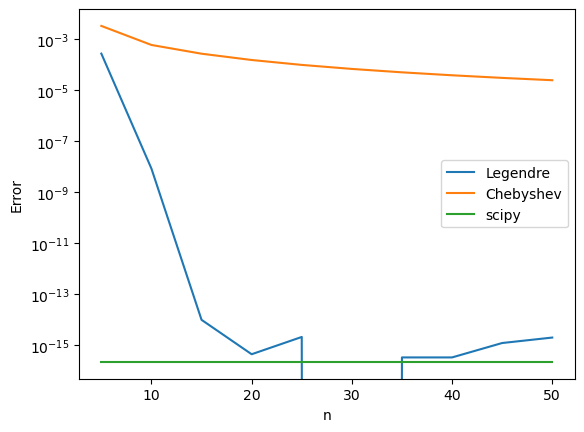

In [10]:
prob5()

The errors behind the plot: the Legendre error drops to the level of round-off by about $n = 15$, close to the error of `quad()` (for $n = 30$ it is exactly 0, which a log scale can't show, hence the gap in the line), while the Chebyshev error decreases only algebraically, because $g(x) = h(x)\sqrt{1-x^2}$ is not smooth at $\pm 1$.

In [11]:
f = lambda x: 1/np.sqrt(2*np.pi) * np.exp((-x**2)/2)
F = norm.cdf(2) - norm.cdf(-3)
print(f"F = {F:.15f}   quad error = {abs(F - quad(f, -3, 2)[0]):.1e}")
for n in [5, 10, 20, 50]:
    el = abs(F - GaussianQuadrature(n, "legendre").integrate(f, -3, 2))
    ec = abs(F - GaussianQuadrature(n, "chebyshev").integrate(f, -3, 2))
    print(f"n = {n:2}   Legendre error {el:.1e}   Chebyshev error {ec:.1e}")

F = 0.975899970020191   quad error = 2.2e-16
n =  5   Legendre error 2.6e-04   Chebyshev error 3.2e-03
n = 10   Legendre error 8.3e-09   Chebyshev error 5.8e-04
n = 20   Legendre error 4.4e-16   Chebyshev error 1.5e-04
n = 50   Legendre error 2.0e-15   Chebyshev error 2.4e-05


## Multivariate Quadrature

The same set of points $\{z_i\}_{i=1}^n$ and weights $\{w_i\}_{i=1}^n$ can be used in each direction, so the only difference from 1-D quadrature is how the function is shifted and scaled. Let $h : \mathbb{R}^2 \to \mathbb{R}$ and define $g(x, y) = h(x, y)/(w(x)w(y))$ so that

$$\int_{-1}^1\int_{-1}^1 h(x, y)\,dx\,dy = \int_{-1}^1\int_{-1}^1 g(x, y)w(x)w(y)\,dx\,dy \approx \sum_{i=1}^n\sum_{j=1}^n w_iw_jg(z_i, z_j). \tag{10.3}$$

To integrate $f : \mathbb{R}^2 \to \mathbb{R}$ over a box $[a_1, b_1] \times [a_2, b_2]$, set

$$h(x, y) = f\left(\frac{b_1 - a_1}{2}x + \frac{a_1 + b_1}{2}, \frac{b_2 - a_2}{2}y + \frac{a_2 + b_2}{2}\right)$$

so that

$$\int_{a_2}^{b_2}\int_{a_1}^{b_1} f(x)\,dx\,dy = \frac{(b_1 - a_1)(b_2 - a_2)}{4}\int_{-1}^1\int_{-1}^1 h(x, y)\,dx\,dy. \tag{10.4}$$

Combining (10.3) and (10.4) gives the final 2-D Gaussian quadrature formula. Compare it to (10.2).

$$\int_{a_2}^{b_2}\int_{a_1}^{b_1} f(x)\,dx\,dy \approx \frac{(b_1 - a_1)(b_2 - a_2)}{4}\sum_{i=1}^n\sum_{j=1}^n w_iw_jg(z_i, z_j) \tag{10.5}$$

## Problem 6: Double integrals

> **Problem 6.** Write a method for your class that accepts a function $f : \mathbb{R}^2 \to \mathbb{R}$ (which actually accepts two separate arguments, not one array with two elements) and bounds of integration $a_1$, $a_2$, $b_1$, and $b_2$. Use (10.5) to compute the double integral
>
> $$\int_{a_2}^{b_2}\int_{a_1}^{b_1} f(x)\,dx\,dy.$$
>
> Validate your method by comparing it `scipy.integrate.nquad()`. Note carefully that this function has slightly different syntax for the bounds of integration.

The spec's example:

In [12]:
# Integrate f(x,y) = sin(x) + cos(y) over [-10,10] in x and [-1,1] in y.
f = lambda x, y: np.sin(x) + np.cos(y)
nquad(f, [[-10, 10], [-1, 1]])[0]

33.65883939231586

`integrate2d()` is in the class above. The checks use the spec's example and two further integrands with exact values: $\int_{-3}^4\int_{-1}^2 x^2y^2\,dx\,dy = 91$ and $\int_{-7}^8\int_{-5}^6 \sin(x)\cos(y)\,dx\,dy = (\cos 5 - \cos 6)(\sin 8 + \sin 7) \approx -1.11377$, all with $n = 30$. The Legendre results are accurate to near round-off; the Chebyshev results are only accurate to a few digits, for the same reason as in Problem 5.

In [13]:
L, C = GaussianQuadrature(30, "legendre"), GaussianQuadrature(30, "chebyshev")
tests = [(lambda x, y: np.sin(x) + np.cos(y), -10, 10, -1, 1),
         (lambda x, y: x**2 * y**2, -1, 2, -3, 4),
         (lambda x, y: np.sin(x) * np.cos(y), -5, 6, -7, 8)]
for g, a1, b1, a2, b2 in tests:
    exact = nquad(g, [[a1, b1], [a2, b2]])[0]
    lg, ch = L.integrate2d(g, a1, b1, a2, b2), C.integrate2d(g, a1, b1, a2, b2)
    print(f"nquad {exact: .12f}   Legendre {lg: .12f}   Chebyshev {ch: .12f}")
    assert np.isclose(lg, exact, rtol=1e-10)
    assert np.isclose(ch, exact, rtol=1e-2)

assert np.isclose(L.integrate2d(lambda x, y: x**2 * y**2, -1, 2, -3, 4), 91)
assert np.isclose(L.integrate2d(lambda x, y: np.sin(x) * np.cos(y), -5, 6, -7, 8), -1.11376562522167)
assert np.isclose((np.cos(5) - np.cos(6)) * (np.sin(8) + np.sin(7)), -1.11376562522167)
print("integrate2d() agrees with nquad() and the exact values.")

nquad  33.658839392316   Legendre  33.658839392316   Chebyshev  33.684091921056
nquad  91.000000000000   Legendre  91.000000000000   Chebyshev  91.224509326906
nquad -1.113765625222   Legendre -1.113765625222   Chebyshev -1.112318459539
integrate2d() agrees with nquad() and the exact values.


The `test()` helper compares `nquad()` with the Chebyshev version of `integrate2d()` on $x^2y^2$:

In [14]:
def test():
    Q = GaussianQuadrature(30, polytype="chebyshev")
    f = lambda x, y: x**2 * y**2
    return nquad(f, [[-1,2], [-3, 4]])[0], Q.integrate2d(f, -1, 2, -3, 4)

In [15]:
test()

(91.00000000000001, np.float64(91.22450932690555))

> **Note.** Although Gaussian quadrature can obtain reasonable approximations in lower dimensions, it quickly becomes intractable in higher dimensions due to the *curse of dimensionality*. In other words, the number of points and weights required to obtain a good approximation becomes so large that Gaussian quadrature become computationally infeasible. For this reason, high-dimensional integrals are often computed via *Monte Carlo methods*, numerical integration techniques based on random sampling. However, quadrature methods are generally significantly more accurate in lower dimensions than Monte Carlo methods.